# 04 — Model Evaluation, Confusion Matrix & ROC-AUC

**Project:** LoanWise AI  
**Role:** Member 1 (ML Model Development)  

Run this notebook after `03_model_training.ipynb` (or `python -m ml.src.train`) to visualize:
1. Held-out test metrics across Logistic Regression, Decision Tree, and Random Forest.
2. The Confusion Matrix of the selected winning model (discussing False Positives vs. False Negatives).
3. The ROC Curve and ROC-AUC on the 20% held-out test set.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
elif PROJECT_ROOT.name == "ml":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ml.src.data_loader import load_training_data
from ml.src.evaluate import build_comparison_dataframe
from ml.src.preprocessing import prepare_features_and_target
from ml.src.train import METADATA_FILENAME, MODEL_PIPELINE_FILENAME, SAVED_MODELS_DIR

In [2]:
metadata_path = SAVED_MODELS_DIR / METADATA_FILENAME
model_path = SAVED_MODELS_DIR / MODEL_PIPELINE_FILENAME

with open(metadata_path, "r", encoding="utf-8") as fh:
    metadata = json.load(fh)

model_pipeline = joblib.load(model_path)
print("Loaded winning model:", metadata["selected_model"])
display(build_comparison_dataframe(metadata["model_comparison"]))

Loaded winning model: LogisticRegression


,model,cv_accuracy,cv_f1,cv_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,overfitting_gap_f1
0,LogisticRegression,0.8003 ± 0.0458,0.8714 ± 0.0271,0.7268 ± 0.0904,0.8618,0.8400,0.9882,0.9081,0.8452,-0.0370
1,DecisionTreeClassifier,0.7901 ± 0.0610,0.8641 ± 0.0388,0.7008 ± 0.0750,0.8537,0.8317,0.9882,0.9032,0.7687,-0.0333
2,RandomForestClassifier,0.7983 ± 0.0457,0.8703 ± 0.0271,0.7546 ± 0.0823,0.8537,0.8317,0.9882,0.9032,0.8381,-0.0325


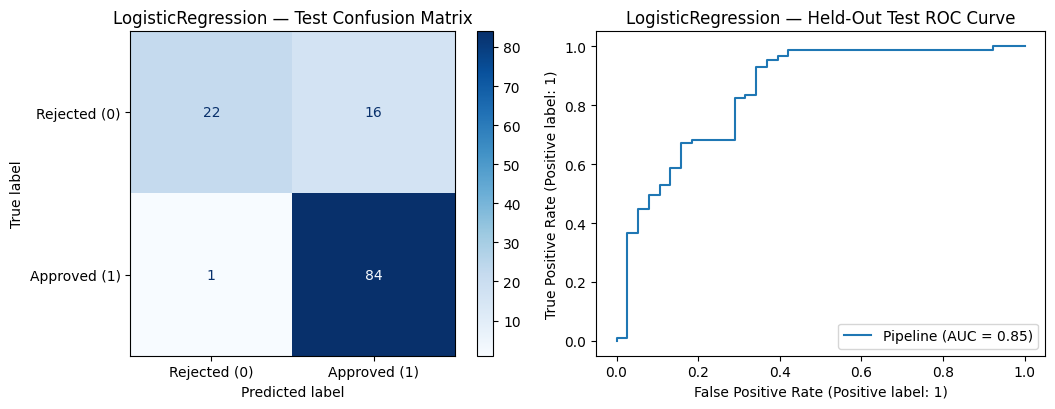

In [3]:
df = load_training_data()
X, y = prepare_features_and_target(df)

_, X_test, _, y_test = train_test_split(
    X,
    y,
    test_size=metadata["dataset_summary"]["test_size"],
    stratify=y,
    random_state=metadata["dataset_summary"]["random_state"],
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_estimator(
    model_pipeline,
    X_test,
    y_test,
    display_labels=["Rejected (0)", "Approved (1)"],
    cmap="Blues",
    ax=axes[0],
)
axes[0].set_title(f"{metadata['selected_model']} — Test Confusion Matrix")

RocCurveDisplay.from_estimator(model_pipeline, X_test, y_test, ax=axes[1])
axes[1].set_title(f"{metadata['selected_model']} — Held-Out Test ROC Curve")
plt.tight_layout()
plt.show()